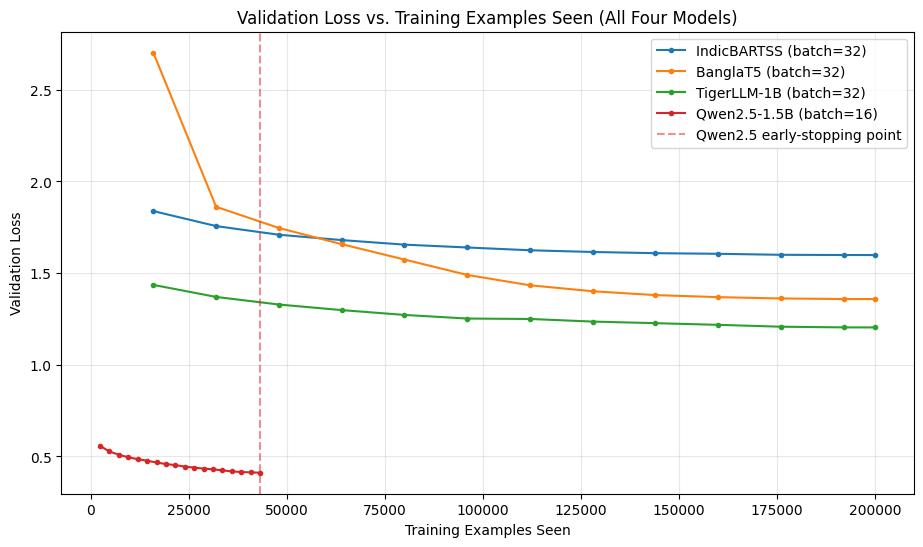

Saved combined_loss_curves.svg and .png


In [ ]:
import matplotlib.pyplot as plt

# Compiled validation loss histories (step, val_loss)
indicbartss = [(500,1.838210),(1000,1.756392),(1500,1.709263),(2000,1.680105),(2500,1.655277),
               (3000,1.639785),(3500,1.624516),(4000,1.615195),(4500,1.608659),(5000,1.605299),
               (5500,1.599818),(6000,1.598660),(6250,1.598496)]

banglat5 = [(500,2.701888),(1000,1.861526),(1500,1.746095),(2000,1.657886),(2500,1.574064),
            (3000,1.490068),(3500,1.433627),(4000,1.401066),(4500,1.380008),(5000,1.368891),
            (5500,1.361627),(6000,1.358584),(6250,1.358516)]

tigerllm = [(500,1.435655),(1000,1.370055),(1500,1.328643),(2000,1.298237),(2500,1.271881),
            (3000,1.252156),(3500,1.249848),(4000,1.235623),(4500,1.226948),(5000,1.217867),
            (5500,1.207626),(6000,1.203994),(6250,1.203630)]

qwen25 = [(150,0.558258),(300,0.527081),(450,0.509298),(600,0.495528),(750,0.485354),
          (900,0.476654),(1050,0.467139),(1200,0.458713),(1350,0.452635),(1500,0.444955),
          (1650,0.438932),(1800,0.433893),(1950,0.429771),(2100,0.424237),(2250,0.418430),
          (2400,0.415288),(2550,0.413355),(2700,0.411318)]

models = {
    "IndicBARTSS (batch=32)": (indicbartss, 32, "tab:blue"),
    "BanglaT5 (batch=32)": (banglat5, 32, "tab:orange"),
    "TigerLLM-1B (batch=32)": (tigerllm, 32, "tab:green"),
    "Qwen2.5-1.5B (batch=16)": (qwen25, 16, "tab:red"),
}

plt.figure(figsize=(11, 6))
for label, (data, batch, color) in models.items():
    steps = [s for s, _ in data]
    losses = [l for _, l in data]
    examples_seen = [s * batch for s in steps]
    plt.plot(examples_seen, losses, label=label, color=color, marker='o', markersize=3)

# Mark Qwen2.5's early stopping point
plt.axvline(x=2700*16, color='tab:red', linestyle='--', alpha=0.5, label='Qwen2.5 early-stopping point')

plt.xlabel('Training Examples Seen')
plt.ylabel('Validation Loss')
plt.title('Validation Loss vs. Training Examples Seen (All Four Models)')
plt.legend()
plt.grid(alpha=0.3)

PROJECT_ROOT = '/content/drive/MyDrive/Bengali Paraphrasing'

plt.savefig(f'{PROJECT_ROOT}/combined_loss_curves.svg', format='svg', bbox_inches='tight')
plt.savefig(f'{PROJECT_ROOT}/combined_loss_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved combined_loss_curves.svg and .png")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = '/content/drive/MyDrive/Bengali Paraphrasing'
# then change the two savefig lines to:
plt.savefig(f'{PROJECT_ROOT}/combined_loss_curves.svg', format='svg', bbox_inches='tight')
plt.savefig(f'{PROJECT_ROOT}/combined_loss_curves.png', dpi=150, bbox_inches='tight')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<Figure size 640x480 with 0 Axes>

# Panel A (left): IndicBARTSS + BanglaT5 — same loss type (seq2seq cross-entropy), same eval set (full 5K validation) — a genuinely valid, apples-to-apples comparison
# Panel B (right): TigerLLM + Qwen2.5 — same loss type (causal LM loss on masked labels)(full 5K validation)

Mounted at /content/drive


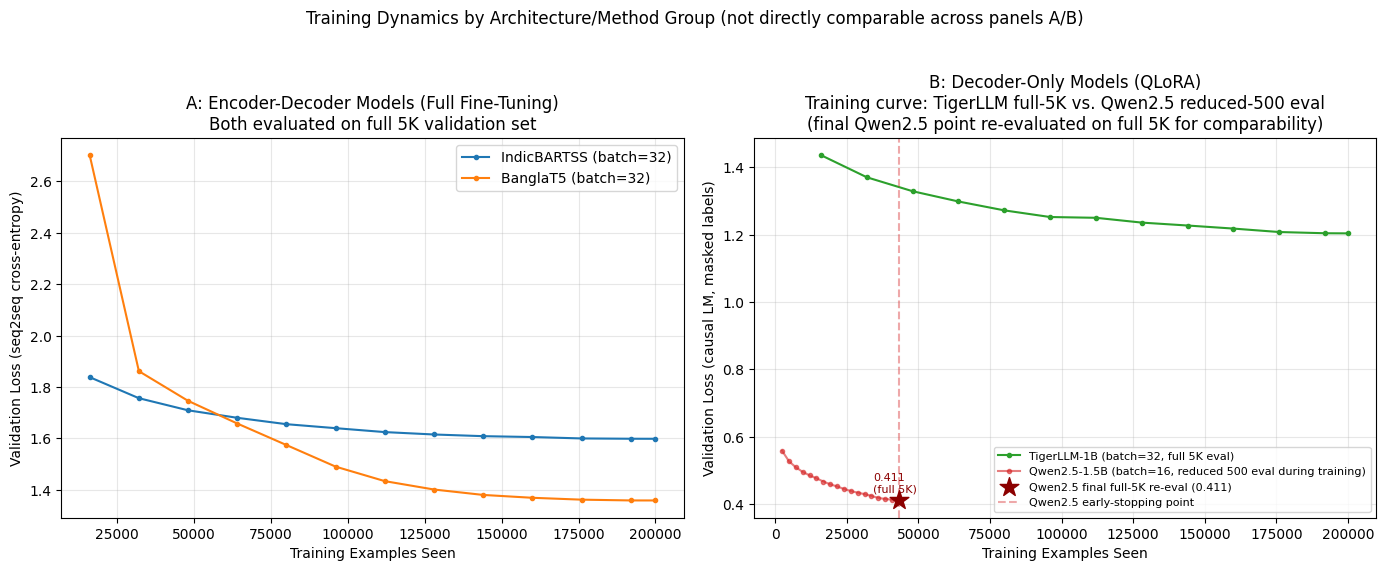

Saved combined_loss_curves_panels_v2.svg and .png


In [2]:
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = '/content/drive/MyDrive/Bengali Paraphrasing'
# --- Data ---
indicbartss = [(500,1.838210),(1000,1.756392),(1500,1.709263),(2000,1.680105),(2500,1.655277),
               (3000,1.639785),(3500,1.624516),(4000,1.615195),(4500,1.608659),(5000,1.605299),
               (5500,1.599818),(6000,1.598660),(6250,1.598496)]

banglat5 = [(500,2.701888),(1000,1.861526),(1500,1.746095),(2000,1.657886),(2500,1.574064),
            (3000,1.490068),(3500,1.433627),(4000,1.401066),(4500,1.380008),(5000,1.368891),
            (5500,1.361627),(6000,1.358584),(6250,1.358516)]

tigerllm = [(500,1.435655),(1000,1.370055),(1500,1.328643),(2000,1.298237),(2500,1.271881),
            (3000,1.252156),(3500,1.249848),(4000,1.235623),(4500,1.226948),(5000,1.217867),
            (5500,1.207626),(6000,1.203994),(6250,1.203630)]

qwen25 = [(150,0.558258),(300,0.527081),(450,0.509298),(600,0.495528),(750,0.485354),
          (900,0.476654),(1050,0.467139),(1200,0.458713),(1350,0.452635),(1500,0.444955),
          (1650,0.438932),(1800,0.433893),(1950,0.429771),(2100,0.424237),(2250,0.418430),
          (2400,0.415288),(2550,0.413355),(2700,0.411318)]

qwen25_full5k_final = (2700, 0.410903)  # genuine post-hoc re-evaluation on full 5K set

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Panel A: Encoder-Decoder models (both full fine-tune, both full 5K eval -- fully comparable) ---
for label, data, batch, color in [
    ("IndicBARTSS (batch=32)", indicbartss, 32, "tab:blue"),
    ("BanglaT5 (batch=32)", banglat5, 32, "tab:orange"),
]:
    steps = [s for s, _ in data]
    losses = [l for _, l in data]
    examples_seen = [s * batch for s in steps]
    ax1.plot(examples_seen, losses, label=label, color=color, marker='o', markersize=3)

ax1.set_xlabel('Training Examples Seen')
ax1.set_ylabel('Validation Loss (seq2seq cross-entropy)')
ax1.set_title('A: Encoder-Decoder Models (Full Fine-Tuning)\nBoth evaluated on full 5K validation set')
ax1.legend()
ax1.grid(alpha=0.3)

# --- Panel B: Decoder-only models (QLoRA) ---
tiger_steps = [s for s, _ in tigerllm]
tiger_losses = [l for _, l in tigerllm]
tiger_examples = [s * 32 for s in tiger_steps]
ax2.plot(tiger_examples, tiger_losses, label="TigerLLM-1B (batch=32, full 5K eval)",
         color="tab:green", marker='o', markersize=3)

qwen_steps = [s for s, _ in qwen25]
qwen_losses = [l for _, l in qwen25]
qwen_examples = [s * 16 for s in qwen_steps]
ax2.plot(qwen_examples, qwen_losses, label="Qwen2.5-1.5B (batch=16, reduced 500 eval during training)",
         color="tab:red", marker='o', markersize=3, alpha=0.6)

# Annotated final point -- genuine full 5K re-evaluation, clearly distinguished
final_x = qwen25_full5k_final[0] * 16
final_y = qwen25_full5k_final[1]
ax2.scatter([final_x], [final_y], color="darkred", marker='*', s=200, zorder=5,
            label=f"Qwen2.5 final full-5K re-eval ({final_y:.3f})")
ax2.annotate(f"{final_y:.3f}\n(full 5K)", xy=(final_x, final_y), xytext=(final_x - 9000, final_y + 0.025),
             fontsize=8, color="darkred")

ax2.axvline(x=2700*16, color='tab:red', linestyle='--', alpha=0.4, label='Qwen2.5 early-stopping point')

ax2.set_xlabel('Training Examples Seen')
ax2.set_ylabel('Validation Loss (causal LM, masked labels)')
ax2.set_title('B: Decoder-Only Models (QLoRA)\nTraining curve: TigerLLM full-5K vs. Qwen2.5 reduced-500 eval\n(final Qwen2.5 point re-evaluated on full 5K for comparability)')
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

plt.suptitle('Training Dynamics by Architecture/Method Group (not directly comparable across panels A/B)', y=1.03)
plt.tight_layout()

plt.savefig(f'{PROJECT_ROOT}/combined_loss_curves_panels_v2.svg', format='svg', bbox_inches='tight')
plt.savefig(f'{PROJECT_ROOT}/combined_loss_curves_panels_v2.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved combined_loss_curves_panels_v2.svg and .png")